<a href="https://colab.research.google.com/github/rkamathshabarish2006/pnemonia_detection/blob/main/newPnemonia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -U kagglehub

In [ ]:
import kagglehub

# Download the latest version of the dataset
path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [ ]:
import os

for root, dirs, files in os.walk(path):
    folder_name = os.path.basename(root).upper()

    if folder_name in ["TRAIN", "TEST", "VAL"]:
        print(root)

/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/val
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/test
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train
/kaggle/input/chest-xray-pneumonia/chest_xray/val
/kaggle/input/chest-xray-pneumonia/chest_xray/test
/kaggle/input/chest-xray-pneumonia/chest_xray/train


In [ ]:
import os

for split in ["train", "test", "val"]:
    split_path = os.path.join(path, split)

    if os.path.exists(split_path):
        normal_path = os.path.join(split_path, "NORMAL")
        pneumonia_path = os.path.join(split_path, "PNEUMONIA")

        normal_count = (
            len(os.listdir(normal_path))
            if os.path.exists(normal_path) else 0
        )

        pneumonia_count = (
            len(os.listdir(pneumonia_path))
            if os.path.exists(pneumonia_path) else 0
        )

        print(f"{split.upper()}")
        print("  NORMAL   :", normal_count)
        print("  PNEUMONIA:", pneumonia_count)
        print()

In [ ]:
!pip install -q -U kagglehub

In [ ]:
import kagglehub
import os

path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Dataset path:")
print(path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset path:
/kaggle/input/chest-xray-pneumonia


In [ ]:
import os

print("Searching dataset...")

for root, dirs, files in os.walk(path):
    folder = os.path.basename(root).lower()

    if folder in ["train", "test", "val"]:
        print(root)

Searching dataset...
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/val
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/test
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train
/kaggle/input/chest-xray-pneumonia/chest_xray/val
/kaggle/input/chest-xray-pneumonia/chest_xray/test
/kaggle/input/chest-xray-pneumonia/chest_xray/train


In [ ]:
import os

train_dir = None
test_dir = None
val_dir = None

for root, dirs, files in os.walk(path):

    folder = os.path.basename(root).lower()

    if folder == "train" and "NORMAL" in [d.upper() for d in dirs]:
        train_dir = root

    elif folder == "test" and "NORMAL" in [d.upper() for d in dirs]:
        test_dir = root

    elif folder == "val" and "NORMAL" in [d.upper() for d in dirs]:
        val_dir = root

print("TRAIN:", train_dir)
print("TEST :", test_dir)
print("VAL  :", val_dir)

TRAIN: /kaggle/input/chest-xray-pneumonia/chest_xray/train
TEST : /kaggle/input/chest-xray-pneumonia/chest_xray/test
VAL  : /kaggle/input/chest-xray-pneumonia/chest_xray/val


In [ ]:
def count_images(folder):

    normal = os.path.join(folder, "NORMAL")
    pneumonia = os.path.join(folder, "PNEUMONIA")

    normal_count = len([
        f for f in os.listdir(normal)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    pneumonia_count = len([
        f for f in os.listdir(pneumonia)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    return normal_count, pneumonia_count


for name, folder in [
    ("TRAIN", train_dir),
    ("TEST", test_dir),
    ("VAL", val_dir)
]:

    if folder:

        normal, pneumonia = count_images(folder)

        print(
            f"{name}: NORMAL={normal}, "
            f"PNEUMONIA={pneumonia}"
        )

TRAIN: NORMAL=1341, PNEUMONIA=3875
TEST: NORMAL=234, PNEUMONIA=390
VAL: NORMAL=8, PNEUMONIA=8


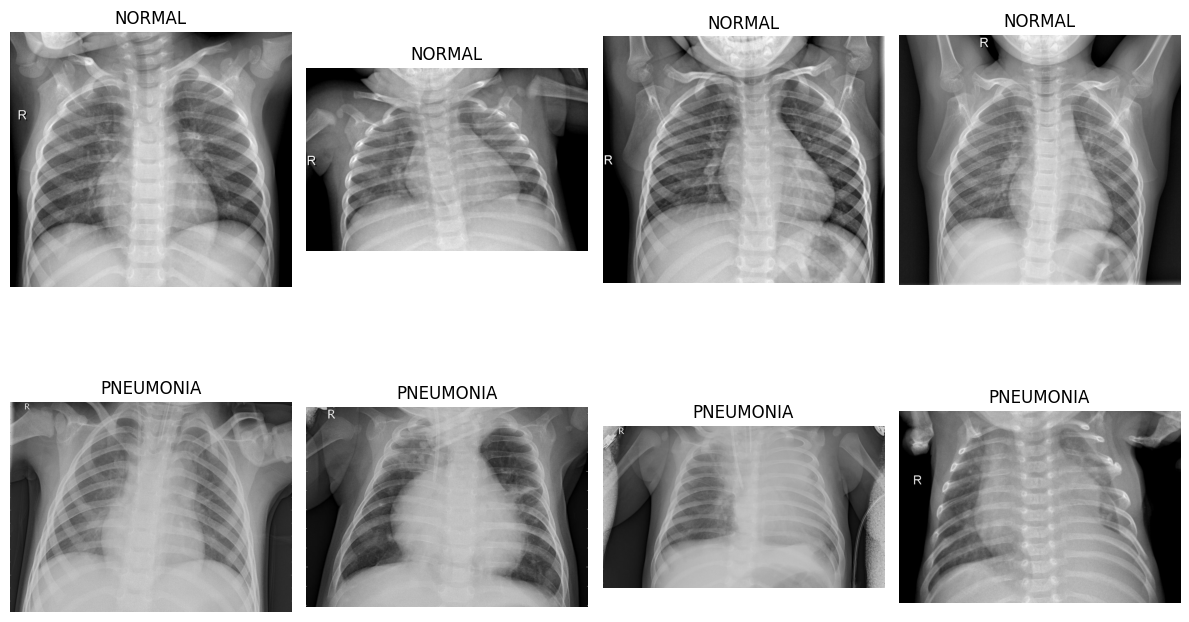

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random
import glob

normal_images = glob.glob(
    os.path.join(train_dir, "NORMAL", "*")
)

pneumonia_images = glob.glob(
    os.path.join(train_dir, "PNEUMONIA", "*")
)

plt.figure(figsize=(12, 8))

samples = (
    random.sample(normal_images, 4) +
    random.sample(pneumonia_images, 4)
)

for i, img_path in enumerate(samples):

    img = Image.open(img_path)

    plt.subplot(2, 4, i + 1)

    plt.imshow(img, cmap="gray")

    if "NORMAL" in img_path:
        plt.title("NORMAL")
    else:
        plt.title("PNEUMONIA")

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=False
)

print("Classes:", train_ds.class_names)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [ ]:
import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=False
)

print("Classes:", train_ds.class_names)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [ ]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.05),

    layers.RandomZoom(0.10),

    layers.RandomContrast(0.10),

], name="data_augmentation")

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.15),
], name="augmentation")

print("Data augmentation ready.")

Data augmentation ready.


In [ ]:
import os

normal_dir = os.path.join(train_dir, "NORMAL")
pneumonia_dir = os.path.join(train_dir, "PNEUMONIA")

normal_count = len([
    f for f in os.listdir(normal_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

pneumonia_count = len([
    f for f in os.listdir(pneumonia_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("NORMAL images:", normal_count)
print("PNEUMONIA images:", pneumonia_count)

total = normal_count + pneumonia_count

class_weight = {
    0: total / (2 * normal_count),
    1: total / (2 * pneumonia_count)
}

print("\nClass weights:")
print(class_weight)

NORMAL images: 1341
PNEUMONIA images: 3875

Class weights:
{0: 1.9448173005219984, 1: 0.6730322580645162}


In [ ]:
class TransformerBlock(layers.Layer):

    def __init__(
        self,
        embed_dim,
        num_heads,
        ff_dim,
        dropout=0.1
    ):
        super().__init__()

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim
        )

        self.ffn = tf.keras.Sequential([
            layers.Dense(ff_dim, activation="gelu"),
            layers.Dropout(dropout),
            layers.Dense(embed_dim)
        ])

        self.norm1 = layers.LayerNormalization(
            epsilon=1e-6
        )

        self.norm2 = layers.LayerNormalization(
            epsilon=1e-6
        )

        self.dropout1 = layers.Dropout(dropout)
        self.dropout2 = layers.Dropout(dropout)

    def call(self, inputs, training=False):

        attention_output = self.attention(
            inputs,
            inputs,
            training=training
        )

        attention_output = self.dropout1(
            attention_output,
            training=training
        )

        x = self.norm1(
            inputs + attention_output
        )

        ffn_output = self.ffn(
            x,
            training=training
        )

        ffn_output = self.dropout2(
            ffn_output,
            training=training
        )

        return self.norm2(
            x + ffn_output
        )

print("Transformer block ready.")

Transformer block ready.


In [ ]:
cnn = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

cnn.trainable = False

print("CNN created.")
print("CNN output shape:", cnn.output_shape)

CNN created.
CNN output shape: (None, 7, 7, 1280)


In [ ]:
inputs = layers.Input(
    shape=(224, 224, 3),
    name="chest_xray"
)

# Data augmentation
x = data_augmentation(inputs)

# CNN feature extraction
x = cnn(
    x,
    training=False
)

# Convert CNN channels to Transformer embedding
x = layers.Conv2D(
    256,
    kernel_size=1,
    padding="same",
    name="feature_projection"
)(x)

# Convert feature map into tokens
x = layers.Reshape(
    (-1, 256),
    name="image_tokens"
)(x)

# Transformer block 1
x = TransformerBlock(
    embed_dim=256,
    num_heads=8,
    ff_dim=512,
    dropout=0.1
)(x)

# Transformer block 2
x = TransformerBlock(
    embed_dim=256,
    num_heads=8,
    ff_dim=512,
    dropout=0.1
)(x)

# Pool Transformer features
x = layers.GlobalAveragePooling1D()(x)

x = layers.Dropout(0.4)(x)

# Classification layers
x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

# Output
outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="pneumonia_probability"
)(x)

model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="CNN_Transformer_Pneumonia"
)

model.summary()

Model: "CNN_Transformer_Pneumonia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ chest_xray (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_projection (Conv2D)     │ (None, 7, 7, 256)      │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ image_tokens (Reshape)          │ (None, 49, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_2             │ (None, 49, 256)        │     2,367,488 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_3             │ (None, 49, 256)        │     2,367,488 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_probability (Dense)   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,145,508 (34.89 MB)

 Trainable params: 5,095,937 (19.44 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
cnn.trainable = True

# Freeze early CNN layers
for layer in cnn.layers[:-60]:
    layer.trainable = False

# Keep BatchNormalization frozen
for layer in cnn.layers:
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

print(
    "Trainable CNN layers:",
    sum(
        layer.trainable
        for layer in cnn.layers
    )
)

Trainable CNN layers: 47


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss=tf.keras.losses.BinaryCrossentropy(
        label_smoothing=0.05
    ),

    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),

        tf.keras.metrics.Precision(
            name="precision"
        ),

        tf.keras.metrics.Recall(
            name="recall"
        ),

        tf.keras.metrics.AUC(
            name="auc"
        )
    ]
)

In [ ]:
fine_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weight,
    callbacks=callbacks
)

Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - accuracy: 0.9302 - auc: 0.9791 - loss: 0.2626 - precision: 0.9813 - recall: 0.9229
Epoch 1: val_auc did not improve from 1.00000
163/163 ━━━━━━━━━━━━━━━━━━━━ 60s 247ms/step - accuracy: 0.9354 - auc: 0.9807 - loss: 0.2554 - precision: 0.9825 - recall: 0.9295 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.2394 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 1.0000e-05
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.9363 - auc: 0.9845 - loss: 0.2447 - precision: 0.9834 - recall: 0.9280
Epoch 2: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.

Epoch 2: val_auc did not improve from 1.00000
163/163 ━━━━━━━━━━━━━━━━━━━━ 38s 229ms/step - accuracy: 0.9394 - auc: 0.9841 - loss: 0.2430 - precision: 0.9842 - recall: 0.9334 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.2273 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 1.0000e-05
Epoch 3/15
163/163 ━━━━━━━━━

In [ ]:
results = model.evaluate(
    test_ds,
    verbose=1
)

print("\nFINAL RESULTS")

for name, value in zip(
    model.metrics_names,
    results
):
    print(f"{name}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 149ms/step - accuracy: 0.8894 - auc: 0.9568 - loss: 0.3199 - precision: 0.8983 - recall: 0.9282

FINAL RESULTS
loss: 0.3199
compile_metrics: 0.8894


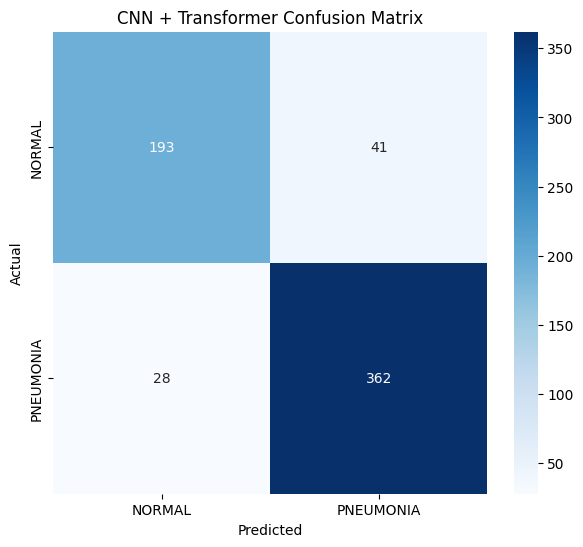

              precision    recall  f1-score   support

      NORMAL     0.8733    0.8248    0.8484       234
   PNEUMONIA     0.8983    0.9282    0.9130       390

    accuracy                         0.8894       624
   macro avg     0.8858    0.8765    0.8807       624
weighted avg     0.8889    0.8894    0.8887       624



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(
        images,
        verbose=0
    )

    predictions = (
        predictions >= 0.5
    ).astype(int).flatten()

    y_true.extend(
        labels.numpy().astype(int).flatten()
    )

    y_pred.extend(predictions)

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "NORMAL",
        "PNEUMONIA"
    ],
    yticklabels=[
        "NORMAL",
        "PNEUMONIA"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN + Transformer Confusion Matrix")
plt.show()

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "NORMAL",
            "PNEUMONIA"
        ],
        digits=4
    )
)

In [ ]:
from google.colab import files

files.download(
    "/content/pneumonia_cnn_transformer_final.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model loaded successfully.
Model input shape: (None, 224, 224, 3)

Upload your chest X-ray image:


Saving WhatsApp Image 2026-10-02 at 9.44.00 PM.jpeg to WhatsApp Image 2026-10-02 at 9.44.00 PM (4).jpeg
Uploaded file: WhatsApp Image 2026-10-02 at 9.44.00 PM (4).jpeg

Input shape: (1, 224, 224, 3)
Input range: 0.0 to 236.0

Raw model probability: 0.8290524482727051

Checking model layers...
All required layers found successfully.
Grad-CAM model created successfully.
Feature map shape: (1, 7, 7, 1280)
Gradient shape: (1, 7, 7, 1280)


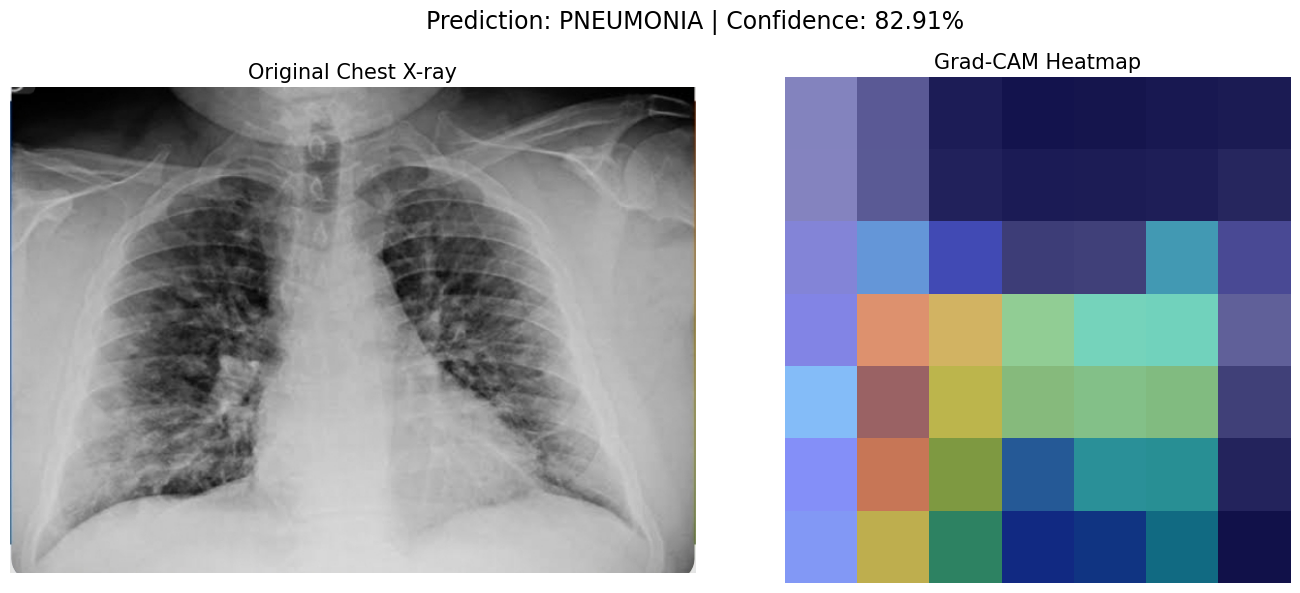


          PNEUMONIA DETECTION RESULT
Image      : WhatsApp Image 2026-10-02 at 9.44.00 PM (4).jpeg
Prediction : PNEUMONIA
Confidence : 82.91%
⚠️ The model predicts PNEUMONIA.


In [ ]:
# ============================================================
# SINGLE CELL — PNEUMONIA PREDICTION + GRAD-CAM
# ============================================================

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# ============================================================
# STEP 1 — CHECK MODEL
# ============================================================

if "model" not in globals():
    raise RuntimeError(
        "ERROR: 'model' is not loaded.\n"
        "Please load your trained model before running this cell."
    )

print("Model loaded successfully.")
print("Model input shape:", model.input_shape)


# ============================================================
# STEP 2 — UPLOAD CHEST X-RAY
# ============================================================

print("\nUpload your chest X-ray image:")

uploaded = files.upload()

if len(uploaded) == 0:
    raise RuntimeError("No image was uploaded.")

filename = list(uploaded.keys())[0]

print("Uploaded file:", filename)


# ============================================================
# STEP 3 — LOAD AND PREPROCESS IMAGE
# ============================================================

img = Image.open(filename).convert("RGB")

# Keep original image for display
original_img = img.copy()

# Resize to model input size
img = img.resize((224, 224))

# Convert to NumPy
img_array = np.array(img).astype("float32")

# Add batch dimension
input_tensor = np.expand_dims(img_array, axis=0)

print("\nInput shape:", input_tensor.shape)
print("Input range:", input_tensor.min(), "to", input_tensor.max())


# ============================================================
# STEP 4 — NORMAL PREDICTION
# ============================================================

prediction = model.predict(
    input_tensor,
    verbose=0
)

probability = float(prediction[0][0])

print("\nRaw model probability:", probability)


# Convert probability to result
if probability >= 0.5:
    result = "PNEUMONIA"
    confidence = probability * 100
else:
    result = "NORMAL"
    confidence = (1 - probability) * 100


# ============================================================
# STEP 5 — CHECK REQUIRED LAYERS
# ============================================================

required_layers = [
    "efficientnetb0",
    "feature_projection",
    "image_tokens",
    "transformer_block_2",
    "transformer_block_3",
    "global_average_pooling1d_1",
    "dropout_18",
    "dense_9",
    "dropout_19",
    "pneumonia_probability"
]

print("\nChecking model layers...")

available_layers = [layer.name for layer in model.layers]

missing_layers = [
    layer_name
    for layer_name in required_layers
    if layer_name not in available_layers
]

if missing_layers:

    print("\nWARNING: The following layers were not found:")
    for layer_name in missing_layers:
        print(" -", layer_name)

    print("\nAvailable model layers:")
    for layer in model.layers:
        print(" -", layer.name)

    print(
        "\nPrediction will be shown, but Grad-CAM cannot "
        "be generated with these layer names."
    )

    # Show prediction only
    plt.figure(figsize=(7, 7))
    plt.imshow(original_img)
    plt.axis("off")
    plt.title(
        f"Prediction: {result}\n"
        f"Confidence: {confidence:.2f}%",
        fontsize=15
    )
    plt.show()

else:

    print("All required layers found successfully.")


    # ========================================================
    # STEP 6 — GET MODEL LAYERS
    # ========================================================

    cnn = model.get_layer("efficientnetb0")

    feature_projection = model.get_layer(
        "feature_projection"
    )

    image_tokens = model.get_layer(
        "image_tokens"
    )

    transformer1 = model.get_layer(
        "transformer_block_2"
    )

    transformer2 = model.get_layer(
        "transformer_block_3"
    )

    gap = model.get_layer(
        "global_average_pooling1d_1"
    )

    dropout1 = model.get_layer(
        "dropout_18"
    )

    dense1 = model.get_layer(
        "dense_9"
    )

    dropout2 = model.get_layer(
        "dropout_19"
    )

    output_layer = model.get_layer(
        "pneumonia_probability"
    )


    # ========================================================
    # STEP 7 — BUILD GRAD-CAM MODEL
    # ========================================================

    grad_input = tf.keras.Input(
        shape=(224, 224, 3),
        name="gradcam_input"
    )

    # EfficientNet
    x = cnn(
        grad_input,
        training=False
    )

    # Save CNN feature maps
    cnn_features = x

    # CNN → projection
    x = feature_projection(x)

    # Feature map → tokens
    x = image_tokens(x)

    # Transformer block 1
    x = transformer1(
        x,
        training=False
    )

    # Transformer block 2
    x = transformer2(
        x,
        training=False
    )

    # Classification head
    x = gap(x)

    x = dropout1(
        x,
        training=False
    )

    x = dense1(x)

    x = dropout2(
        x,
        training=False
    )

    output = output_layer(x)

    grad_model = tf.keras.Model(
        inputs=grad_input,
        outputs=[
            cnn_features,
            output
        ]
    )

    print("Grad-CAM model created successfully.")


    # ========================================================
    # STEP 8 — CALCULATE GRADIENTS
    # ========================================================

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            input_tensor,
            training=False
        )

        probability_tensor = predictions[:, 0]

    gradients = tape.gradient(
        probability_tensor,
        conv_outputs
    )

    print(
        "Feature map shape:",
        conv_outputs.shape
    )

    print(
        "Gradient shape:",
        gradients.shape
    )


    # ========================================================
    # STEP 9 — GENERATE GRAD-CAM HEATMAP
    # ========================================================

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    conv_outputs_single = conv_outputs[0]

    pooled_gradients_single = pooled_gradients[0]

    heatmap = tf.reduce_sum(
        conv_outputs_single *
        pooled_gradients_single,
        axis=-1
    )

    # Remove negative values
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize
    heatmap_max = tf.reduce_max(
        heatmap
    )

    heatmap = heatmap / (
        heatmap_max +
        tf.keras.backend.epsilon()
    )

    heatmap = heatmap.numpy()


    # ========================================================
    # STEP 10 — FINAL RESULT
    # ========================================================

    probability_value = float(
        probability_tensor.numpy()[0]
    )

    if probability_value >= 0.5:

        result = "PNEUMONIA"
        confidence = probability_value * 100

    else:

        result = "NORMAL"
        confidence = (1 - probability_value) * 100


    # ========================================================
    # STEP 11 — DISPLAY ORIGINAL + GRAD-CAM
    # ========================================================

    plt.figure(figsize=(14, 6))


    # Original X-ray
    plt.subplot(1, 2, 1)

    plt.imshow(
        original_img,
        cmap="gray"
    )

    plt.axis("off")

    plt.title(
        "Original Chest X-ray",
        fontsize=15
    )


    # Grad-CAM
    plt.subplot(1, 2, 2)

    plt.imshow(
        original_img,
        cmap="gray"
    )

    plt.imshow(
        heatmap,
        cmap="jet",
        alpha=0.45
    )

    plt.axis("off")

    plt.title(
        "Grad-CAM Heatmap",
        fontsize=15
    )


    plt.suptitle(
        f"Prediction: {result} | "
        f"Confidence: {confidence:.2f}%",
        fontsize=17
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# STEP 12 — FINAL PRINTED RESULT
# ============================================================

print("\n" + "=" * 55)
print("          PNEUMONIA DETECTION RESULT")
print("=" * 55)

print("Image      :", filename)
print("Prediction :", result)
print(f"Confidence : {confidence:.2f}%")

print("=" * 55)

if result == "PNEUMONIA":
    print("⚠️ The model predicts PNEUMONIA.")
else:
    print("✅ The model predicts NORMAL.")

print("=" * 55)

In [ ]:
model.save("/content/pneumonia_cnn_transformer_final.keras")

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers


# ============================================================
# DEFINE YOUR CUSTOM TRANSFORMER BLOCK
# ============================================================

class TransformerBlock(layers.Layer):

    def __init__(
        self,
        embed_dim,
        num_heads,
        ff_dim,
        dropout=0.1,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.dropout_rate = dropout

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim
        )

        self.ffn = tf.keras.Sequential([
            layers.Dense(
                ff_dim,
                activation="gelu"
            ),
            layers.Dropout(dropout),
            layers.Dense(embed_dim)
        ])

        self.norm1 = layers.LayerNormalization(
            epsilon=1e-6
        )

        self.norm2 = layers.LayerNormalization(
            epsilon=1e-6
        )

        self.dropout1 = layers.Dropout(dropout)
        self.dropout2 = layers.Dropout(dropout)


    def call(self, inputs, training=False):

        attention_output = self.attention(
            inputs,
            inputs,
            training=training
        )

        attention_output = self.dropout1(
            attention_output,
            training=training
        )

        x = self.norm1(
            inputs + attention_output
        )

        ffn_output = self.ffn(
            x,
            training=training
        )

        ffn_output = self.dropout2(
            ffn_output,
            training=training
        )

        return self.norm2(
            x + ffn_output
        )


    def get_config(self):

        config = super().get_config()

        config.update({
            "embed_dim": self.embed_dim,
            "num_heads": self.num_heads,
            "ff_dim": self.ff_dim,
            "dropout": self.dropout_rate
        })

        return config


print("TransformerBlock defined successfully!")

TransformerBlock defined successfully!


In [ ]:
import tensorflow as tf

try:
    # Load the model from the saved file using the defined TransformerBlock
    saved_model = tf.keras.models.load_model(
        '/content/pneumonia_cnn_transformer_final.keras',
        custom_objects={'TransformerBlock': TransformerBlock}
    )
    print("Saved model loaded successfully!")

    # Evaluate the model on test dataset
    print("Evaluating on test dataset...")
    metrics = saved_model.evaluate(test_ds, verbose=0)

    # Print each metric clearly
    print("\n================ TEST METRICS ================")
    for name, val in zip(saved_model.metrics_names, metrics):
        print(f"{name.upper():<15}: {val:.4f}")
    print("==============================================")
except Exception as e:
    print(f"Error loading or evaluating the model: {e}")
    print("Please ensure you run the cell that defines 'TransformerBlock' and datasets ('test_ds') first.")

Error loading or evaluating the model: File not found: filepath=/content/pneumonia_cnn_transformer_final.keras. Please ensure the file is an accessible `.keras` zip file.
Please ensure you run the cell that defines 'TransformerBlock' and datasets ('test_ds') first.
